# MVSA-Single: Dataset Preprocessing
**BITS F464 Machine Learning · Multimodal Sentiment Analysis Using Text and Image Data**

This notebook prepares the data and builds the features that the model notebook needs. It runs on Kaggle with the
dataset attached (`vincemarcs/mvsasingle`).

**Before running on Kaggle:** *Add Input → vincemarcs/mvsasingle*, then in *Settings* turn on
**Accelerator: GPU** (CLIP runs on it) and **Internet: On** (to download CLIP and the small helper libraries).

| Step | What it does |
|---|---|
| 0 | Setup and configuration |
| 1 | Load posts and labels |
| 2 | **Missing values**: audit and handle missing, corrupt and duplicate data |
| 3 | Derive one label per post (standard MVSA rule) and tag agreement groups |
| 4 | Clean the text (URLs, mentions, hashtags, emojis) |
| 5 | Stratified 8:1:1 split, done **before** anything is fitted |
| 6 | **Feature engineering**: text meta-features, image features, TF-IDF, CLIP |
| 7 | **Normalisation and standardisation**, fitted on the training set only |
| 8 | Save everything for the modelling notebook |

## Step 0: Setup
The three settings you might change are `DATA_ROOT`, `OUT_DIR` and `RUN_CLIP`.
`emoji`, `wordsegment` and `ftfy` are small helper libraries. If they can't be installed, the notebook
switches to simpler built-in fallbacks and still runs.

In [1]:
# Imports and settings; every path can be overridden with an environment variable for local testing
import os, re, sys, json, html, hashlib, subprocess, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import sparse
import joblib
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler

DATA_ROOT      = os.environ.get("MVSA_ROOT", "/kaggle/input")               # where the dataset is mounted
OUT_DIR        = os.environ.get("MVSA_OUT", "/kaggle/working/preprocessed")  # where outputs are written
RUN_CLIP       = os.environ.get("MVSA_RUN_CLIP", "1") == "1"                # set to False to skip CLIP
CLIP_MODEL     = os.environ.get("MVSA_CLIP_MODEL", "openai/clip-vit-base-patch32")  # ViT-B/32
INSTALL_EXTRAS = os.environ.get("MVSA_INSTALL_EXTRAS", "1") == "1"
SEED   = 42
LABELS = ["negative", "neutral", "positive"]
WORKERS = 16          # threads for reading images in parallel (reading files is the slow part)

import socket, time
from io import BytesIO
from functools import lru_cache
from concurrent.futures import ThreadPoolExecutor
_T = {"t": time.perf_counter()}
def tick(step):       # prints how long each step took, so you can see where the time goes
    now = time.perf_counter()
    print(f"\n⏱ {step} took {now - _T['t']:.1f}s")
    _T["t"] = now

def online(host="pypi.org", port=443, timeout=3):
    """Check for internet access, so optional downloads can be skipped instead of hanging."""
    try:
        socket.create_connection((host, port), timeout=timeout).close()
        return True
    except OSError:
        return False
ONLINE = online()
socket.setdefaulttimeout(20)   # so no download can hang forever
print(f"Internet: {'on' if ONLINE else 'OFF: optional libraries and VADER will be skipped, CLIP cannot download'}")
try:
    import torch
    print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE: CLIP will be slow. Settings → Accelerator → GPU'}")
except ImportError:
    pass

# Optional helpers: each import below falls back to None, and later code then uses a built-in alternative
if INSTALL_EXTRAS and ONLINE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--timeout", "15", "--retries", "1",
                    "emoji", "wordsegment", "ftfy"], check=False)

try:
    import emoji
except ImportError:
    emoji = None
try:
    import wordsegment
    wordsegment.load()
except ImportError:
    wordsegment = None
try:
    import ftfy
except ImportError:
    ftfy = None
print(f"emoji: {emoji is not None} | wordsegment: {wordsegment is not None} | ftfy: {ftfy is not None}")
tick("Step 0 (setup)")

for sub in ("features", "artifacts", "figures"):
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)
REPORT = {}   # every count we log ends up in preprocessing_report.json

Internet: on
GPU: Tesla T4
emoji: True | wordsegment: True | ftfy: True

⏱ Step 0 (setup) took 11.1s


## Step 1: Load posts and labels
`labelResultAll.txt` has one line per post: `ID<TAB>text_label,image_label`. The first line is a header.
The text and image for post `ID` are stored as `data/ID.txt` and `data/ID.jpg`.

In [2]:
def find_label_file(root):
    """Search the attached dataset for the label file, since the mount path can vary."""
    for dirpath, _, files in os.walk(root):
        for f in files:
            if f.lower() == "labelresultall.txt":
                return os.path.join(dirpath, f)
    raise FileNotFoundError(f"labelResultAll.txt not found under {root}. Is the MVSA-Single dataset attached?")

LABEL_FILE = find_label_file(DATA_ROOT)
DATA_DIR = os.path.join(os.path.dirname(LABEL_FILE), "data")

def parse_label_file(path):
    """Read the label file into a table with one row per post: id, text_label, image_label."""
    rows = []
    with open(path, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.strip()
            if not line or not line[0].isdigit():      # skips the header line
                continue
            tok = re.split(r"[,\t ]+", line)
            rows.append({"id": tok[0],
                         "text_label":  tok[1].lower() if len(tok) > 1 else None,
                         "image_label": tok[2].lower() if len(tok) > 2 else None})
    return pd.DataFrame(rows)

df = parse_label_file(LABEL_FILE)
REPORT["posts_in_label_file"] = len(df)
print(f"Label file: {LABEL_FILE}\nPosts listed: {len(df)}")
print(df.head())

Label file: /kaggle/input/datasets/vincemarcs/mvsasingle/MVSA_Single/labelResultAll.txt
Posts listed: 4869
  id text_label image_label
0  1    neutral    positive
1  2    neutral    positive
2  3    neutral    positive
3  4   positive    positive
4  5   positive    positive


## Step 2: Missing values (and other broken data)
In a tabular dataset, "missing values" means empty cells. In a multimodal dataset, a value can be missing
or unusable in several ways, so each one is checked separately:

| Problem | How it's detected | What we do | Why |
|---|---|---|---|
| Label missing or not one of pos/neu/neg | value check | **drop** | A sample with no valid target can't be used for supervised learning |
| Text file missing | file doesn't exist | **drop** | There is no text to embed |
| Text file empty | empty after `strip()` | **keep and flag** | An empty caption is real social-media behaviour. The image can still carry the sentiment |
| Image missing | file doesn't exist | **drop** | CLIP needs an image. Missing modalities are simulated later, in a controlled way |
| Image corrupt or truncated | `PIL.verify()` + `load()` fail | **drop** | It would crash or corrupt feature extraction |
| Exact duplicate (same text *and* same image bytes) | text + MD5 of the image | **keep the first copy** | Copies would be counted twice and could end up in both train and test |
| Garbled characters (e.g. `â€™`) | decoding fallback + `ftfy` | **repair** | Mis-decoded characters break tokenisation |

We **don't impute** (fill in) missing text or images. Imputing raw text or pixels isn't meaningful, and
the model notebook's robustness test masks one modality with its *training-set mean embedding*, which
is the right place to deal with a missing modality. Imputation therefore happens at the feature level, at
evaluation time, rather than here.

All 4,869 posts in this copy have both a text and an image, so most counts below should be 0.
Checking is still part of a reproducible pipeline: it proves the data is clean instead of assuming it.

In [3]:
def read_text(post_id):
    """Read one caption, returning (text, status), where status is ok, empty or missing_file."""
    path = os.path.join(DATA_DIR, f"{post_id}.txt")
    if not os.path.exists(path):
        return None, "missing_file"
    raw = open(path, "rb").read()
    for enc in ("utf-8", "cp1252", "latin-1"):        # latin-1 always succeeds, so this always returns
        try:
            text = raw.decode(enc)
            break
        except UnicodeDecodeError:
            continue
    if ftfy is not None:
        text = ftfy.fix_text(text)                     # repairs mojibake such as "donâ€™t" -> "don't"
    text = text.strip()
    return text, ("ok" if text else "empty")

def inspect_image(post_id):
    """Check that one image exists and decodes, and return its size and MD5 for duplicate detection."""
    path = next((os.path.join(DATA_DIR, f"{post_id}{e}") for e in (".jpg", ".jpeg", ".png")
                 if os.path.exists(os.path.join(DATA_DIR, f"{post_id}{e}"))), None)
    if path is None:
        return {"image_path": None, "image_status": "missing_file"}
    with open(path, "rb") as f:
        data = f.read()                                # read the file once; everything below uses these bytes
    try:
        with Image.open(BytesIO(data)) as im:
            im.verify()                                # checks the file structure
        with Image.open(BytesIO(data)) as im:
            im.load()                                  # decodes the pixels, which catches truncated files
            w, h = im.size
    except Exception:
        return {"image_path": path, "image_status": "corrupt"}
    return {"image_path": path, "image_status": "ok", "width": w, "height": h,
            "image_md5": hashlib.md5(data).hexdigest()}

with ThreadPoolExecutor(WORKERS) as ex:               # files are read in parallel: several times faster
    texts = list(ex.map(read_text, df["id"]))
    img_info = pd.DataFrame(list(ex.map(inspect_image, df["id"])), index=df.index)
df["text_raw"]    = [t for t, _ in texts]
df["text_status"] = [s for _, s in texts]
df = pd.concat([df, img_info], axis=1)
df["label_valid"] = df["text_label"].isin(LABELS) & df["image_label"].isin(LABELS)

print("Missing cells per column (before handling):")
print(df.isna().sum().to_string())
tick("Step 2a (reading texts + checking images)")

Missing cells per column (before handling):
id              0
text_label      0
image_label     0
text_raw        0
text_status     0
image_path      0
image_status    0
width           0
height          0
image_md5       0
label_valid     0

⏱ Step 2a (reading texts + checking images) took 81.1s


In [4]:
n0 = len(df)
audit = []
def drop(mask, issue, why):
    """Remove the flagged posts and record how many went and why, for the audit table."""
    global df
    audit.append({"issue": issue, "posts": int(mask.sum()), "action": "dropped", "reason": why})
    df = df[~mask].copy()

drop(~df["label_valid"],                        "invalid or missing label", "no valid target")
drop(df["text_status"].eq("missing_file"),      "text file missing",        "nothing to embed")
drop(df["image_status"].eq("missing_file"),     "image file missing",       "nothing to embed")
drop(df["image_status"].eq("corrupt"),          "image corrupt/truncated",  "cannot be decoded")
dup = df.duplicated(subset=["text_raw", "image_md5"], keep="first")
drop(dup,                                        "exact duplicate post",     "would be counted twice / leak")

df["text_empty_raw"] = df["text_status"].eq("empty").astype(int)
audit.append({"issue": "text file empty", "posts": int(df["text_empty_raw"].sum()),
              "action": "kept + flagged", "reason": "image can still carry the sentiment"})
audit = pd.DataFrame(audit)
print(audit.to_string(index=False))
print(f"\n{n0} -> {len(df)} posts after handling missing and broken data")

REPORT["missing_value_audit"] = audit.to_dict(orient="records")
REPORT["posts_after_missing_handling"] = len(df)
tick("Step 2b (handling)")

                   issue  posts         action                              reason
invalid or missing label      0        dropped                     no valid target
       text file missing      0        dropped                    nothing to embed
      image file missing      0        dropped                    nothing to embed
 image corrupt/truncated      0        dropped                   cannot be decoded
    exact duplicate post     30        dropped       would be counted twice / leak
         text file empty      0 kept + flagged image can still carry the sentiment

4869 -> 4839 posts after handling missing and broken data

⏱ Step 2b (handling) took 0.0s


## Step 3: One label per post, plus agreement tags
This is the standard MVSA rule:
* text and image labels agree → use that label (**agreement**)
* one label is neutral → use the non-neutral one (**soft mismatch**)
* one is positive and the other negative → no single label (**hard mismatch**)

The standard rule *discards* hard mismatches. Here they're **set aside** in a separate file instead, so they
can be evaluated separately later. They are never used for training.
The `mismatch_type` tag is kept on every post so results can be reported per group.

On the full data: 4,484 labelled posts (2,670 / 468 / 1,346 pos / neu / neg) and 355 hard mismatches.

In [5]:
def mismatch_type(t, v):
    """Tag a post by how its text and image labels relate."""
    if t == v:
        return "agreement"
    return "hard_mismatch" if {t, v} == {"positive", "negative"} else "soft_mismatch"

def standard_label(t, v):
    """Apply the standard MVSA rule to get one label; None means a hard mismatch."""
    if t == v:      return t
    if t == "neutral": return v
    if v == "neutral": return t
    return None                                        # hard mismatch

df["mismatch_type"] = [mismatch_type(t, v) for t, v in zip(df.text_label, df.image_label)]
df["label"]         = [standard_label(t, v) for t, v in zip(df.text_label, df.image_label)]

print(df["mismatch_type"].value_counts().to_string())
print("\nLabel distribution (hard mismatches excluded):")
print(df["label"].value_counts().to_string())
REPORT["mismatch_counts"] = df["mismatch_type"].value_counts().to_dict()
REPORT["label_counts"]    = df["label"].value_counts().to_dict()
tick("Step 3")

mismatch_type
agreement        2576
soft_mismatch    1908
hard_mismatch     355

Label distribution (hard mismatches excluded):
label
positive    2670
negative    1346
neutral      468

⏱ Step 3 took 0.0s


## Step 4: Text cleaning
Cleaning is applied in this order (the order matters):
1. **HTML entities**: `&amp;` → `&`
2. **URLs removed**: `http://t.co/...` links carry no sentiment, and the link *count* is kept as a feature
3. **Mentions** → `@user`: the specific username is noise, but the fact that someone is addressed is kept
4. **Retweet prefix** `RT @user:` removed
5. **Hashtags segmented**: `#unicornNation` → `unicorn Nation`, `#happyfriday` → `happy friday`. A lot of
   the sentiment in tweets is in hashtags, and CLIP/TF-IDF can't read run-together words
6. **Emojis → words**: 😂 → `face with tears of joy`. CLIP's tokenizer handles emojis poorly, and the words carry the meaning
7. **Elongations shortened**: `soooo` → `soo`. This keeps the emphasis but merges the many spellings into one
8. Whitespace normalised

Case and punctuation are **kept on purpose**. `!!!` and ALL CAPS signal sentiment, CLIP was trained on natural
text, and TF-IDF lowercases by itself. **Stop-words aren't removed** either, because standard lists include
`not`, `no` and `never`, which reverse sentiment.

If a caption is empty after cleaning (e.g. it was only a link), it becomes the placeholder `"no text"` and the
`text_empty` flag is set, so the model can tell that case apart.

In [6]:
# Patterns for each kind of text cleaned below
URL_RE      = re.compile(r"(https?://\S+|www\.\S+|\bt\.co/\S+)", re.I)
MENTION_RE  = re.compile(r"@\w+")
RT_RE       = re.compile(r"^\s*RT\b\s*(@user)?\s*:?\s*", re.I)
HASHTAG_RE  = re.compile(r"#(\w+)")
ELONG_RE    = re.compile(r"(\w)\1{2,}")
EMPTY_PLACEHOLDER = "no text"

@lru_cache(maxsize=None)                               # the same hashtag is only segmented once
def segment_hashtag(tag):
    """Split a hashtag into words: first at case and digit boundaries, then with wordsegment if still one word."""
    split = re.sub(r"(?<=[a-z])(?=[A-Z])|(?<=[A-Za-z])(?=\d)|(?<=\d)(?=[A-Za-z])", " ", tag).replace("_", " ")
    if wordsegment is not None and " " not in split and tag.isalpha() and len(tag) > 5:
        split = " ".join(wordsegment.segment(tag))
    return split

def is_emoji_char(ch):
    if emoji is not None:
        return emoji.is_emoji(ch)
    o = ord(ch)                                         # fallback: symbols in the emoji code-point ranges
    return unicodedata.category(ch) == "So" and (o >= 0x1F000 or 0x2600 <= o <= 0x27BF)

def count_emojis(text):
    return emoji.emoji_count(text) if emoji is not None else sum(is_emoji_char(c) for c in text)

def emojis_to_text(text):
    if emoji is not None:
        return emoji.replace_emoji(text, replace=lambda e, data: f" {data['en'].strip(':').replace('_', ' ')} ")
    text = text.replace("️", "").replace("‍", "")
    return "".join(f" {unicodedata.name(c, '').lower()} " if is_emoji_char(c) else c for c in text)

def clean_text(t):
    """Apply the cleaning steps listed above, in that order."""
    t = html.unescape(t or "")
    t = URL_RE.sub(" ", t)
    t = MENTION_RE.sub("@user", t)
    t = RT_RE.sub("", t)
    t = HASHTAG_RE.sub(lambda m: segment_hashtag(m.group(1)), t)
    t = emojis_to_text(t)
    t = ELONG_RE.sub(r"\1\1", t)
    return re.sub(r"\s+", " ", t).strip()

df["text_clean"] = df["text_raw"].apply(clean_text)
df["text_empty"] = df["text_clean"].eq("").astype(int)
df.loc[df["text_empty"] == 1, "text_clean"] = EMPTY_PLACEHOLDER
REPORT["text_empty_after_cleaning"] = int(df["text_empty"].sum())

pd.set_option("display.max_colwidth", 90)
changed = df[df["text_raw"] != df["text_clean"]]
print(f"{len(changed)} of {len(df)} texts changed by cleaning; "
      f"{df['text_empty'].sum()} were empty afterwards (set to '{EMPTY_PLACEHOLDER}').\n")
print(changed[["text_raw", "text_clean"]].head(8).to_string(index=False))
tick("Step 4 (text cleaning)")

4199 of 4839 texts changed by cleaning; 45 were empty afterwards (set to 'no text').

                                                                                                                         text_raw                                                                                                     text_clean
                                                                                     How I feel today #legday #jelly #aching #gym                                                                      How I feel today leg day jelly aching gym
            grattis min griskulting!!!???? va bara tvungen oki s? sch ? @ingenkommeratttrodig #pig #happybday #wow #lovely #cut¡­              grattis min griskulting!!!???? va bara tvungen oki s? sch ? @user pig happy bday wow lovely cut¡­
                                                     RT @polynminion: The moment I found my favourite tV character. #PROFOUNDLOVE                                                    The moment

## Step 5: Train / validation / test split, *before* fitting anything
**Why split now?** Every step from here on *learns* from the data: TF-IDF learns a vocabulary, and the
scaler learns means and standard deviations. If those were fitted on all the data, information from the test
set would leak into training and the test score would be too optimistic. So we split first and fit only on `train`.

* **8:1:1, stratified**. Stratification is on *label × agreement group*, so each split has the same
  class balance **and** the same share of soft mismatches, which the per-group evaluation needs.
* **Grouped by cleaned text.** MVSA has retweets: the same caption appears with different images.
  `StratifiedGroupKFold` keeps identical captions in the same split, so the model can't score well just by
  remembering a caption it saw in training.
* Hard mismatches form a fourth, evaluation-only set: `hard`.

Sizes on the full data: 3,591 / 446 / 447.

In [7]:
# Hard mismatches have no single label, so they stay out of the three modelling splits
main = df[df["mismatch_type"] != "hard_mismatch"].reset_index(drop=True)
hard = df[df["mismatch_type"] == "hard_mismatch"].reset_index(drop=True)

def group_keys(frame):
    key = frame["text_clean"].str.lower().str.replace(r"\W+", " ", regex=True).str.strip()
    return np.where(frame["text_empty"] == 1, "__empty__" + frame["id"], key)   # empty captions aren't one group

# Stratify on label x agreement group, and group by caption so a retweeted caption can't cross splits
strata = (main["label"] + "|" + main["mismatch_type"]).values
groups = group_keys(main)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)       # only appears for tiny strata
    # 1 fold of 10 becomes test; then 1 of the remaining 9 becomes validation, giving 8:1:1
    rest_idx, test_idx = next(StratifiedGroupKFold(10, shuffle=True, random_state=SEED).split(main, strata, groups))
    tr, va = next(StratifiedGroupKFold(9, shuffle=True, random_state=SEED)
                  .split(rest_idx, strata[rest_idx], groups[rest_idx]))

main["split"] = "train"
main.loc[rest_idx[va], "split"] = "val"
main.loc[test_idx, "split"] = "test"
hard["split"] = "hard"

# Safety check: stop the notebook if any caption appears in two splits
g = pd.Series(groups)
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = set(g[main.split == a]) & set(g[main.split == b])
    assert not overlap, f"caption leak between {a} and {b}"
print("No caption appears in more than one split.\n")

summary = pd.concat([
    main.groupby("split").size().rename("posts"),
    pd.crosstab(main.split, main.label, normalize="index").mul(100).round(1).add_suffix(" %"),
    pd.crosstab(main.split, main.mismatch_type, normalize="index").mul(100).round(1).add_suffix(" %"),
], axis=1).loc[["train", "val", "test"]]
print(summary.to_string())
print(f"\nhard (evaluation only): {len(hard)} posts")
REPORT["split_sizes"] = {**main.split.value_counts().to_dict(), "hard": len(hard)}
tick("Step 5 (split)")

posts = pd.concat([main, hard], ignore_index=True)    # one table, one row order, used for every feature
SPLITS = ["train", "val", "test", "hard"]

No caption appears in more than one split.

       posts  negative %  neutral %  positive %  agreement %  soft_mismatch %
split                                                                        
train   3591        30.0       10.5        59.5         57.6             42.4
val      446        30.0       11.9        58.1         57.2             42.8
test     447        30.0        8.7        61.3         56.6             43.4

hard (evaluation only): 355 posts

⏱ Step 5 (split) took 4.9s


## Step 6: Feature engineering
Four groups of features, each answering a different question:

| Group | Features | Dim | Purpose |
|---|---|---|---|
| **6a Text meta** | length, word count, #hashtags, #mentions, #URLs, #emojis, `!`, `?`, upper-case ratio, is-retweet, empty flag, VADER scores | ~15 | Cheap, interpretable signals that help explain the model |
| **6b Image** | colour histogram (8 bins × RGB), brightness, contrast, saturation, colourfulness, size, aspect ratio, greyscale flag | 24 + 8 | A colour histogram plus simple affective cues: bright, saturated images tend to read positive |
| **6c TF-IDF** | word 1–2-grams, fitted on train | ≤ 5,000 | Used by the baseline model. Bigrams capture `not good` |
| **6d CLIP** | ViT-B/32 text and image embeddings + their cosine similarity | 512 + 512 + 1 | The main features. The cosine similarity is the first **agreement feature** for the gated fusion |

The other two agreement features, the Jensen–Shannon divergence and classifier confidence, come from
the unimodal classifiers' *predictions*. They are built in the modelling stage, not here.

### 6a: Text meta-features
These are computed from the **raw** text, because cleaning removes exactly what is being counted.

In [8]:
def text_meta(raw):
    """Count simple signals in one raw caption."""
    raw = raw or ""
    letters = [c for c in raw if c.isalpha()]
    return {
        "n_chars":     len(raw),
        "n_words":     len(raw.split()),
        "n_hashtags":  len(HASHTAG_RE.findall(raw)),
        "n_mentions":  len(MENTION_RE.findall(raw)),
        "n_urls":      len(URL_RE.findall(raw)),
        "n_emojis":    count_emojis(raw),
        "n_exclaim":   raw.count("!"),
        "n_question":  raw.count("?"),
        "upper_ratio": sum(c.isupper() for c in letters) / max(1, len(letters)),
        "is_retweet":  int(bool(re.match(r"^\s*RT\b", raw))),
    }

text_feats = pd.DataFrame([text_meta(t) for t in posts["text_raw"]])
text_feats["text_empty"] = posts["text_empty"].values

# VADER is a sentiment lexicon built for social media. It's optional: it needs a small NLTK download.
try:
    if not ONLINE:
        raise RuntimeError("no internet")
    import nltk
    nltk.download("vader_lexicon", quiet=True)
    from nltk.sentiment import SentimentIntensityAnalyzer
    sia = SentimentIntensityAnalyzer()
    vader = pd.DataFrame([sia.polarity_scores(t) for t in posts["text_clean"]]).add_prefix("vader_")
    text_feats = pd.concat([text_feats, vader], axis=1)
    print("VADER scores added.")
except Exception as e:
    print(f"VADER skipped ({type(e).__name__}); everything else is unaffected.")

print(text_feats.describe().T[["mean", "std", "min", "max"]].round(3).to_string())
tick("Step 6a")

VADER scores added.
                  mean     std    min     max
n_chars         91.707  32.641  3.000  250.00
n_words         13.169   5.206  1.000   29.00
n_hashtags       1.537   2.554  0.000   15.00
n_mentions       0.773   0.979  0.000   10.00
n_urls           0.335   0.653  0.000    3.00
n_emojis         0.018   0.195  0.000    6.00
n_exclaim        0.260   0.749  0.000   15.00
n_question       0.882   5.057  0.000  117.00
upper_ratio      0.148   0.153  0.000    1.00
is_retweet       0.409   0.492  0.000    1.00
text_empty       0.009   0.096  0.000    1.00
vader_neg        0.136   0.173  0.000    1.00
vader_neu        0.708   0.208  0.000    1.00
vader_pos        0.156   0.187  0.000    1.00
vader_compound   0.051   0.518 -0.988    0.98

⏱ Step 6a took 1.8s


### 6b: Image features
The colour histogram uses 8 bins per channel, and each channel is **normalised to sum to 1**
so that image size doesn't matter. Colourfulness is the Hasler–Süsstrunk measure.

In [9]:
def image_features(path, bins=8, size=128):
    """Return one image's colour histogram and simple cues such as brightness and colourfulness."""
    with Image.open(path) as im:
        im.draft("RGB", (size * 2, size * 2))         # JPEG trick: decode at reduced resolution, much faster
        rgb = im.convert("RGB").resize((size, size))
    a = np.asarray(rgb, dtype=np.float32)
    hist = np.concatenate([np.histogram(a[..., c], bins=bins, range=(0, 256))[0] for c in range(3)])
    hist = hist.astype(np.float32) / (size * size)
    gray = a @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    sat = np.asarray(rgb.convert("HSV"), dtype=np.float32)[..., 1]
    rg, yb = a[..., 0] - a[..., 1], 0.5 * (a[..., 0] + a[..., 1]) - a[..., 2]
    colourfulness = np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean())
    meta = {
        "brightness":    gray.mean() / 255,
        "contrast":      gray.std() / 255,
        "saturation":    sat.mean() / 255,
        "colourfulness": colourfulness / 255,
        "is_grayscale":  int(np.abs(a[..., 0] - a[..., 1]).mean() < 2 and np.abs(a[..., 1] - a[..., 2]).mean() < 2),
    }
    return hist, meta

with ThreadPoolExecutor(WORKERS) as ex:
    feats = list(ex.map(image_features, posts["image_path"]))
colour_hist = np.vstack([h for h, _ in feats])
img_feats = pd.DataFrame([m for _, m in feats])
img_feats["width"]  = posts["width"].values
img_feats["height"] = posts["height"].values
img_feats["log_aspect"] = np.log(posts["width"].values / posts["height"].values)
print(img_feats.describe().T[["mean", "std", "min", "max"]].round(3).to_string())
tick("Step 6b (image features)")

                  mean      std     min       max
brightness       0.468    0.175   0.027     0.994
contrast         0.234    0.066   0.000     0.477
saturation       0.294    0.169   0.000     0.948
colourfulness    0.165    0.099   0.000     0.836
is_grayscale     0.047    0.211   0.000     1.000
width          551.114  105.118  48.000   600.000
height         528.052  220.407  48.000  1199.000
log_aspect       0.105    0.383  -1.185     1.798

⏱ Step 6b (image features) took 24.1s


### 6c: TF-IDF (fitted on train only)
`sublinear_tf` uses `1 + log(tf)`, so a word repeated five times doesn't count five times as much.
`min_df=2` drops words that appear in only one training post; they can't generalise.

In [10]:
# Learn the vocabulary from training posts only, then transform every split with it
is_train = (posts["split"] == "train").values
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=5000, sublinear_tf=True)
tfidf.fit(posts.loc[is_train, "text_clean"])
X_tfidf = tfidf.transform(posts["text_clean"])
print(f"TF-IDF vocabulary: {len(tfidf.vocabulary_)} terms; matrix {X_tfidf.shape}")
tick("Step 6c")

TF-IDF vocabulary: 5000 terms; matrix (4839, 5000)

⏱ Step 6c took 0.3s


### 6d: CLIP embeddings (frozen ViT-B/32)
Each text and image goes through CLIP **once**, and the embeddings are saved, so every later experiment is a
fast scikit-learn fit. Texts longer than CLIP's 77-token limit are truncated; tweets rarely are.
Takes about 2–4 minutes on a Kaggle GPU. **Without a GPU it can take 20+ minutes**, so check the GPU line printed in Step 0.

In [11]:
clip_text = clip_image = clip_cos = None
if RUN_CLIP:
    import torch
    from transformers import CLIPModel, CLIPProcessor
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = CLIPModel.from_pretrained(CLIP_MODEL).to(device).eval()
    proc  = CLIPProcessor.from_pretrained(CLIP_MODEL)
    max_len = model.config.text_config.max_position_embeddings        # 77 for CLIP

    def as_tensor(out):   # newer transformers versions return an output object instead of a tensor
        return out if torch.is_tensor(out) else out.pooler_output

    def load_for_clip(path):
        with Image.open(path) as im:
            im.draft("RGB", (224, 224))                # CLIP only needs 224×224, so skip decoding full size
            return im.convert("RGB")

    @torch.no_grad()
    def clip_encode(texts, paths, bs=128 if device == "cuda" else 32):
        """Embed all posts in batches and scale each vector to unit length. CLIP stays frozen (no gradients)."""
        T, I = [], []
        pool = ThreadPoolExecutor(WORKERS)
        t0 = time.perf_counter()
        for s in range(0, len(texts), bs):
            tok = proc.tokenizer(list(texts[s:s + bs]), padding=True, truncation=True,
                                 max_length=max_len, return_tensors="pt").to(device)
            imgs = list(pool.map(load_for_clip, paths[s:s + bs]))
            pix = proc.image_processor(images=imgs, return_tensors="pt").to(device)
            T.append(torch.nn.functional.normalize(as_tensor(model.get_text_features(**tok)), dim=-1).cpu())
            I.append(torch.nn.functional.normalize(as_tensor(model.get_image_features(**pix)), dim=-1).cpu())
            done = min(s + bs, len(texts))
            if (s // bs) % 5 == 0 or done == len(texts):
                el = time.perf_counter() - t0
                print(f"  {done}/{len(texts)} posts, {el:.0f}s elapsed, ~{el / done * (len(texts) - done):.0f}s left")
        pool.shutdown()
        return torch.cat(T).numpy(), torch.cat(I).numpy()

    print(f"Encoding {len(posts)} posts with {CLIP_MODEL} on {device} ...")
    clip_text, clip_image = clip_encode(posts["text_clean"].tolist(), posts["image_path"].tolist())
    clip_cos = (clip_text * clip_image).sum(axis=1)          # both are unit length, so dot product = cosine
    print(f"text {clip_text.shape}, image {clip_image.shape}")
    print("Mean text–image cosine by group:")
    print(pd.Series(clip_cos).groupby(posts["mismatch_type"].values).mean().round(4).to_string())
else:
    print("RUN_CLIP is False: CLIP skipped.")
tick("Step 6d (CLIP)")

Encoding 4839 posts with openai/clip-vit-base-patch32 on cuda ...
  128/4839 posts, 9s elapsed, ~315s left
  768/4839 posts, 13s elapsed, ~68s left
  1408/4839 posts, 17s elapsed, ~41s left
  2048/4839 posts, 21s elapsed, ~29s left
  2688/4839 posts, 26s elapsed, ~20s left
  3328/4839 posts, 30s elapsed, ~14s left
  3968/4839 posts, 34s elapsed, ~8s left
  4608/4839 posts, 39s elapsed, ~2s left
  4839/4839 posts, 40s elapsed, ~0s left
text (4839, 512), image (4839, 512)
Mean text–image cosine by group:
agreement        0.2803
hard_mismatch    0.2722
soft_mismatch    0.2697

⏱ Step 6d (CLIP) took 68.8s


## Step 7: Normalisation and standardisation
**Normalisation** and **standardisation** are different things, and each feature group gets the one that suits it:

| Features | Treatment | Why |
|---|---|---|
| Counts and sizes (`n_chars`, `n_hashtags`, `width`, …) | `log1p`, then **standardise** | They're right-skewed (a few very long tweets or huge images). `log1p` compresses the tail, then `z = (x − μ_train) / σ_train` |
| Ratios and scores (`brightness`, `upper_ratio`, VADER, CLIP cosine) | **standardise** | Puts them on the same scale, so regularised models (LR, SVM) penalise them evenly and gradient-based models (MLP) converge |
| Binary flags (`is_retweet`, `text_empty`, `is_grayscale`) | **left as 0/1** | Already on a natural scale and easier to interpret |
| Colour histogram | **normalised** (each channel sums to 1, done in 6b) | Makes it independent of image size. It's a distribution, so it isn't shifted |
| TF-IDF | **L2-normalised** per row (built into `TfidfVectorizer`) | Long and short tweets become comparable |
| CLIP embeddings | **L2-normalised** to unit length (done in 6d) | This is how CLIP is meant to be compared (cosine). If a classifier needs standardised inputs, put a `StandardScaler` inside its `Pipeline` in the modelling notebook so it is also fitted on train only |

Tree models (random forest) don't need scaling, but it doesn't hurt them. LR, SVM and MLP do need it.
The scaler's μ and σ come **only from the training split**. Val/test/hard means won't be exactly 0, and that's expected.

In [12]:
meta = pd.concat([text_feats, img_feats], axis=1)
if clip_cos is not None:
    meta["clip_cosine"] = clip_cos

BINARY_COLS = [c for c in ["is_retweet", "text_empty", "is_grayscale"] if c in meta]
LOG_COLS    = [c for c in ["n_chars", "n_words", "n_hashtags", "n_mentions", "n_urls", "n_emojis",
                           "n_exclaim", "n_question", "width", "height"] if c in meta]
SCALE_COLS  = [c for c in meta.columns if c not in BINARY_COLS]

# Fit the scaler on the training split only, then apply it to every split, which prevents test-set leakage
meta_raw = meta.copy()
meta[LOG_COLS] = np.log1p(meta[LOG_COLS])
scaler = StandardScaler().fit(meta.loc[is_train, SCALE_COLS])
meta[SCALE_COLS] = scaler.transform(meta[SCALE_COLS])
META_COLS = SCALE_COLS + BINARY_COLS
meta = meta[META_COLS]

print("Mean / std of the standardised columns, averaged over columns, per split:")
print(pd.DataFrame({s: [meta.loc[posts.split.values == s, SCALE_COLS].mean().mean(),
                        meta.loc[posts.split.values == s, SCALE_COLS].std().mean()] for s in SPLITS},
                   index=["avg mean", "avg std"]).round(3).to_string())

Mean / std of the standardised columns, averaged over columns, per split:
          train    val   test   hard
avg mean    0.0 -0.023 -0.020 -0.025
avg std     1.0  0.959  1.001  0.904


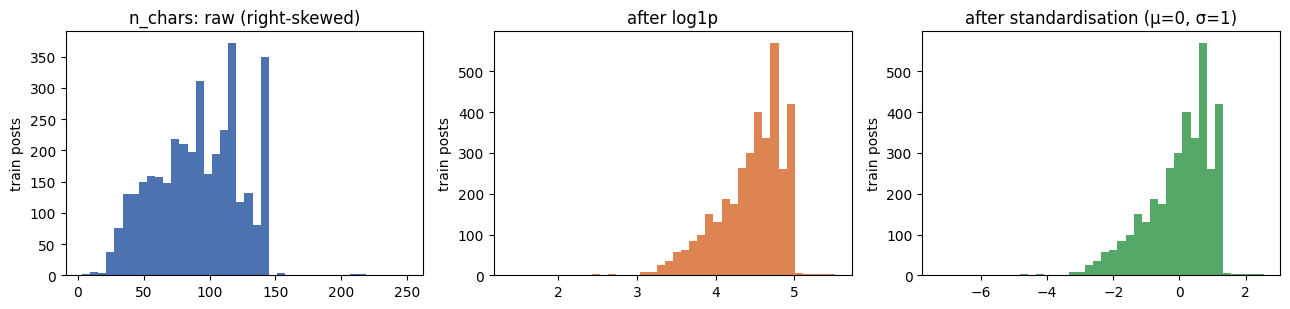

In [13]:
# Plot one feature at each stage, to show what the transformations do
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].hist(meta_raw.loc[is_train, "n_chars"], bins=40, color="#4C72B0")
ax[0].set_title("n_chars: raw (right-skewed)")
ax[1].hist(np.log1p(meta_raw.loc[is_train, "n_chars"]), bins=40, color="#DD8452")
ax[1].set_title("after log1p")
ax[2].hist(meta.loc[is_train, "n_chars"], bins=40, color="#55A868")
ax[2].set_title("after standardisation (μ=0, σ=1)")
for a in ax: a.set_ylabel("train posts")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "scaling_n_chars.png"), dpi=150)
plt.show()

## Step 8: Save everything
One file per feature group per split. Row *i* of every file is the post in line *i* of `<split>_ids.txt`.
```
preprocessed/
  posts_preprocessed.csv        all posts: id, split, raw + clean text, both labels, label, mismatch_type, flags
  preprocessing_report.json     every count logged above
  features/<split>_ids.txt      split ∈ train, val, test, hard
  features/<split>_meta.npy     standardised meta-features (column names in meta_columns.json)
  features/<split>_colorhist.npy
  features/<split>_tfidf.npz
  features/<split>_clip_text.npy, <split>_clip_image.npy
  artifacts/tfidf.joblib, scaler.joblib   fitted on train; reuse for any new data
```

In [14]:
# Write one file per feature group per split, in the same row order as <split>_ids.txt
FEAT = os.path.join(OUT_DIR, "features")
for s in SPLITS:
    m = (posts["split"] == s).values
    np.savetxt(os.path.join(FEAT, f"{s}_ids.txt"), posts.loc[m, "id"].values, fmt="%s")
    np.save(os.path.join(FEAT, f"{s}_meta.npy"), meta.loc[m].to_numpy(np.float32))
    np.save(os.path.join(FEAT, f"{s}_colorhist.npy"), colour_hist[m])
    sparse.save_npz(os.path.join(FEAT, f"{s}_tfidf.npz"), X_tfidf[m])
    if clip_text is not None:
        np.save(os.path.join(FEAT, f"{s}_clip_text.npy"), clip_text[m])
        np.save(os.path.join(FEAT, f"{s}_clip_image.npy"), clip_image[m])

with open(os.path.join(FEAT, "meta_columns.json"), "w") as f:
    json.dump(META_COLS, f, indent=1)
joblib.dump(tfidf, os.path.join(OUT_DIR, "artifacts", "tfidf.joblib"))
joblib.dump({"scaler": scaler, "scale_cols": SCALE_COLS, "log_cols": LOG_COLS, "binary_cols": BINARY_COLS},
            os.path.join(OUT_DIR, "artifacts", "scaler.joblib"))

keep = ["id", "split", "text_raw", "text_clean", "text_label", "image_label", "label", "mismatch_type",
        "text_empty", "image_path", "width", "height"]
posts[keep].to_csv(os.path.join(OUT_DIR, "posts_preprocessed.csv"), index=False)

REPORT.update({"clip_model": CLIP_MODEL if RUN_CLIP else None, "tfidf_vocab": len(tfidf.vocabulary_),
               "meta_columns": META_COLS, "seed": SEED})
with open(os.path.join(OUT_DIR, "preprocessing_report.json"), "w") as f:
    json.dump(REPORT, f, indent=1, default=int)

for root, _, files in os.walk(OUT_DIR):
    for fn in sorted(files):
        p = os.path.join(root, fn)
        print(f"{os.path.relpath(p, OUT_DIR):38s} {os.path.getsize(p) / 1024:9.1f} KB")

posts_preprocessed.csv                    1421.2 KB
preprocessing_report.json                    1.6 KB
figures/scaling_n_chars.png                 40.7 KB
artifacts/scaler.joblib                      1.9 KB
artifacts/tfidf.joblib                     182.2 KB
features/hard_clip_image.npy               710.1 KB
features/hard_clip_text.npy                710.1 KB
features/hard_colorhist.npy                 33.4 KB
features/hard_ids.txt                        1.7 KB
features/hard_meta.npy                      33.4 KB
features/hard_tfidf.npz                     34.7 KB
features/meta_columns.json                   0.3 KB
features/test_clip_image.npy               894.1 KB
features/test_clip_text.npy                894.1 KB
features/test_colorhist.npy                 42.0 KB
features/test_ids.txt                        2.1 KB
features/test_meta.npy                      42.0 KB
features/test_tfidf.npz                     36.7 KB
features/train_clip_image.npy             7182.1 KB
features/tra

## Loading the outputs in the modelling notebook
```python
import numpy as np, pandas as pd, json
from scipy import sparse
D = "/kaggle/input/<your-preprocessed-dataset>/preprocessed/features"   # or /kaggle/working/preprocessed/features
posts = pd.read_csv(D + "/../posts_preprocessed.csv", dtype={"id": str}).set_index("id")
def load(split):
    ids = np.loadtxt(f"{D}/{split}_ids.txt", dtype=str)
    y   = posts.loc[ids, "label"].values            # NaN for the 'hard' split: use text_label / image_label there
    return {"ids": ids, "y": y, "group": posts.loc[ids, "mismatch_type"].values,
            "clip_text": np.load(f"{D}/{split}_clip_text.npy"), "clip_image": np.load(f"{D}/{split}_clip_image.npy"),
            "meta": np.load(f"{D}/{split}_meta.npy"), "hist": np.load(f"{D}/{split}_colorhist.npy"),
            "tfidf": sparse.load_npz(f"{D}/{split}_tfidf.npz")}
train, val, test, hard = (load(s) for s in ["train", "val", "test", "hard"])
X_early = np.hstack([train["clip_text"], train["clip_image"]])         # early-fusion input
```
To reuse these outputs in other notebooks without re-running CLIP: *Save Version → Output → New Dataset*.